# Task 58: False-Positive/False-Negative Analysis and Calibration

Inspect held-out errors, fit a manual Platt calibration model and threshold on validation data, then compare raw versus calibrated confusion metrics and reliability.

Validation-fit Platt slope/intercept: 1.297 0.374 selected threshold: 0.325
Raw test confusion/metrics: {'accuracy': np.float64(0.819672131147541), 'precision': np.float64(0.7894736842105263), 'recall': np.float64(0.9090909090909091), 'f1': np.float64(0.8450704225352113), 'TP': 30, 'TN': 20, 'FP': 8, 'FN': 3}
Calibrated test confusion/metrics: {'accuracy': np.float64(0.8032786885245902), 'precision': np.float64(0.7560975609756098), 'recall': np.float64(0.9393939393939394), 'f1': np.float64(0.8378378378378378), 'TP': 31, 'TN': 18, 'FP': 10, 'FN': 2}
False positives: 10


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Raw probability,Calibrated probability
0,59,0,0,174,249,0,1,143,1,0.0,1,0,2,0.619,0.652
9,59,1,2,126,218,1,1,134,0,2.2,1,1,1,0.679,0.725
10,56,1,2,130,256,1,0,142,1,0.6,1,1,1,0.595,0.622
16,64,1,2,140,335,0,1,158,0,0.0,2,0,2,0.911,0.953
20,62,0,2,130,263,0,1,97,0,1.2,1,1,3,0.620,0.654
40,54,1,1,192,283,0,0,195,0,0.0,2,1,3,0.604,0.634
47,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0.426,0.405
57,58,1,0,100,234,0,1,156,0,0.1,2,1,3,0.468,0.458
59,67,1,2,152,212,0,0,150,0,0.8,1,0,3,0.606,0.636
60,60,1,2,140,185,0,0,155,0,3.0,1,0,2,0.543,0.555


False negatives: 2


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Raw probability,Calibrated probability
7,64,0,0,130,303,0,1,122,0,2.0,1,2,2,0.235,0.178
28,45,1,0,104,208,0,0,148,1,3.0,1,0,2,0.109,0.062


Error counts by age band:


,rows,false_positives,false_negatives
Age band,,,
≤45,14,0,1
46–55,19,2,0
56–65,22,7,1
>65,6,1,0


Raw / calibrated expected calibration error: 0.1084 0.0707


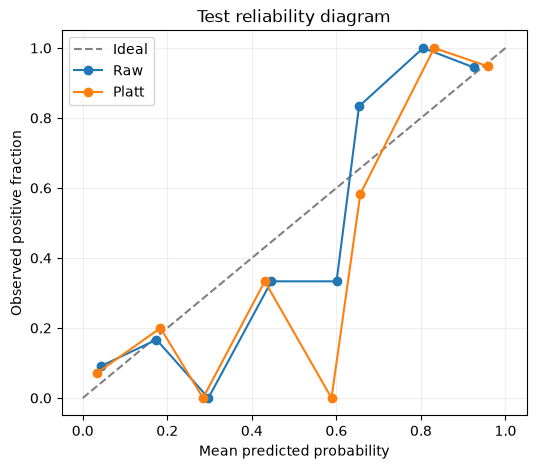

Threshold tuning is validation-only. Lower thresholds may catch more positives at the expense of false alarms; the preferred trade-off depends on clinical workflow and costs.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_58_Error_Analysis_and_Calibration/heart.csv'),Path('Heart_Disease_Tasks/Task_58_Error_Analysis_and_Calibration/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)

def stratified_indices(labels,fraction,seed):
    rng=np.random.default_rng(seed);first=[];second=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));first.extend(ids[:cut]);second.extend(ids[cut:])
    rng.shuffle(first);rng.shuffle(second);return np.array(first),np.array(second)
trainval,test=stratified_indices(y,.8,58);train_local,val_local=stratified_indices(y[trainval],.8,59);train,val=trainval[train_local],trainval[val_local]
Xtr,Xv,Xte=X[train],X[val],X[test];ytr,yv,yte=y[train],y[val],y[test]
mean,scale=Xtr.mean(0),Xtr.std(0);scale[scale==0]=1;Xtr,Xv,Xte=(Xtr-mean)/scale,(Xv-mean)/scale,(Xte-mean)/scale
class Logistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1400):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y;self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def proba(self,x):return 1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))
model=Logistic().fit(Xtr,ytr)

def metrics(actual,pred):
    tp=np.sum((actual==1)&(pred==1));tn=np.sum((actual==0)&(pred==0));fp=np.sum((actual==0)&(pred==1));fn=np.sum((actual==1)&(pred==0))
    precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.
    return {'accuracy':(tp+tn)/len(actual),'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.,'TP':int(tp),'TN':int(tn),'FP':int(fp),'FN':int(fn)}
def sigmoid(z):return 1/(1+np.exp(-np.clip(z,-35,35)))
def logit(p):return np.log(np.clip(p,1e-6,1-1e-6)/(1-np.clip(p,1e-6,1-1e-6)))

# Fit Platt scaling on validation probabilities only, using gradient descent.
validation_probability=model.proba(Xv);validation_logit=logit(validation_probability)
slope,intercept=1.,0.
for _ in range(1500):
    calibrated=sigmoid(slope*validation_logit+intercept);error=calibrated-yv
    slope-=.03*(np.mean(error*validation_logit)+.01*slope);intercept-=.03*error.mean()
cal_validation=sigmoid(slope*validation_logit+intercept)
def f1(actual,pred):return metrics(actual,pred)['f1']
thresholds=np.linspace(.25,.75,21)
threshold_scores=[f1(yv,(cal_validation>=t).astype(int)) for t in thresholds]
selected_threshold=float(thresholds[int(np.argmax(threshold_scores))])
raw_probability=model.proba(Xte);calibrated_probability=sigmoid(slope*logit(raw_probability))
raw_prediction=(raw_probability>=.5).astype(int);cal_prediction=(calibrated_probability>=selected_threshold).astype(int)
print('Validation-fit Platt slope/intercept:',round(slope,3),round(intercept,3),'selected threshold:',selected_threshold)
print('Raw test confusion/metrics:',metrics(yte,raw_prediction))
print('Calibrated test confusion/metrics:',metrics(yte,cal_prediction))

# Recover original held-out examples by index, and inspect FP/FN rows directly.
test_rows=data.iloc[test].reset_index(drop=True).copy();test_rows['Actual']=yte;test_rows['Raw probability']=raw_probability;test_rows['Calibrated probability']=calibrated_probability;test_rows['Predicted']=cal_prediction
test_rows['Error type']=np.where((yte==0)&(cal_prediction==1),'False positive',np.where((yte==1)&(cal_prediction==0),'False negative','Correct'))
false_positives=test_rows[test_rows['Error type']=='False positive'];false_negatives=test_rows[test_rows['Error type']=='False negative']
print('False positives:',len(false_positives));display(false_positives[features+['Raw probability','Calibrated probability']].head(12).round(3))
print('False negatives:',len(false_negatives));display(false_negatives[features+['Raw probability','Calibrated probability']].head(12).round(3))
test_rows['Age band']=pd.cut(test_rows['age'],[0,45,55,65,120],labels=['≤45','46–55','56–65','>65'])
pattern=test_rows.groupby('Age band',observed=False).agg(rows=('Actual','size'),false_positives=('Error type',lambda s:int((s=='False positive').sum())),false_negatives=('Error type',lambda s:int((s=='False negative').sum())))
print('Error counts by age band:');display(pattern)

def calibration_table(probability,labels,bins=8):
    edges=np.linspace(0,1,bins+1);records=[];ece=0.
    for i in range(bins):
        mask=(probability>=edges[i])&(probability<(edges[i+1]) if i<bins-1 else probability<=edges[i+1])
        if mask.any():
            confidence=float(probability[mask].mean());observed=float(labels[mask].mean());ece+=mask.mean()*abs(confidence-observed)
            records.append({'Bin':f'{edges[i]:.2f}–{edges[i+1]:.2f}','Count':int(mask.sum()),'Mean predicted':confidence,'Observed positive rate':observed})
    return ece,pd.DataFrame(records)
raw_ece,raw_bins=calibration_table(raw_probability,yte);cal_ece,cal_bins=calibration_table(calibrated_probability,yte)
print('Raw / calibrated expected calibration error:',round(raw_ece,4),round(cal_ece,4))
fig,ax=plt.subplots(figsize=(6,5));ax.plot([0,1],[0,1],linestyle='--',color='gray',label='Ideal')
for name,table in [('Raw',raw_bins),('Platt',cal_bins)]:ax.plot(table['Mean predicted'],table['Observed positive rate'],marker='o',label=name)
ax.set_xlabel('Mean predicted probability');ax.set_ylabel('Observed positive fraction');ax.set_title('Test reliability diagram');ax.legend();ax.grid(alpha=.2);plt.show()
print('Threshold tuning is validation-only. Lower thresholds may catch more positives at the expense of false alarms; the preferred trade-off depends on clinical workflow and costs.')